# Appendix Experiments

This notebook evaluates density control and event-alignment quality on real data.


## A. Density-Control Ablation

Compare AffineGS with and without adaptive Gaussian density control.


In [1]:
import json
import sys
import time
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from tqdm.notebook import tqdm

# 与 utils.painter 中 EXP1/EXP2 的字体及 PDF 嵌入设置保持一致。
plt.rcParams.update({
    "font.family": "Arial",
    "axes.unicode_minus": False,
    "pdf.fonttype": 42,
})


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "generator").is_dir() and (path / "methods").is_dir():
            return path
    raise RuntimeError("Cannot find project root. Please run this notebook inside the project directory.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager
from methods.affinegs.gaussian_flow.config import GaussianFlowConfig
from methods.affinegs.gaussian_flow.training import run_gaussian_flow
from utils.metrics import AEE, RMSE

DENSITY_OUTPUT_DIR = PROJECT_ROOT / "output" / "APPENDIX_density_control"
DENSITY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_PATH = DENSITY_OUTPUT_DIR / "density-control-ablation-100-samples.json"

# 与 EXP2 的 Datasets 部分保持一致。
DATA_ROOT = Path("/media/newdisk/datasets_piv/piv_cai/train")
dataset_specs = [
    {"name": "JHTDB-isotropic", "file_prefix": "JHTDB_isotropic1024_hd"},
    {"name": "DNS-turbulence", "file_prefix": "DNS_turbulence"},
    {"name": "SQG", "file_prefix": "SQG"},
]

flow_names = [spec["name"] for spec in dataset_specs]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


CMax fused extension: OK
Using device: cuda
Using device: cuda


In [2]:
seed = 42
samples_per_dataset = 100
file_idx_range = range(1, 1201)
iterations = 300


def set_all_seeds(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)


def select_dataset_samples():
    selected = {}
    for spec in dataset_specs:
        samples = []
        for file_idx in file_idx_range:
            path = DATA_ROOT / f"{spec['file_prefix']}_{file_idx:05d}.npz"
            if not path.is_file():
                continue
            samples.append({"file_idx": file_idx, "file_path": str(path)})
            if len(samples) == samples_per_dataset:
                break
        if len(samples) != samples_per_dataset:
            raise RuntimeError(
                f"{spec['name']}: found {len(samples)} files, need {samples_per_dataset} in {DATA_ROOT}"
            )
        selected[spec["name"]] = samples
    return selected


def make_simulated_event_data(flow_source):
    cfg_evts = config_events()
    cfg_evts.height, cfg_evts.width = flow_source.field.h, flow_source.field.w
    cfg_evts.time_length = 4.01
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05
    loader = EventManager(
        source_type="simulator", path=None, cfg=cfg_evts,
        flow_func=flow_source.evaluate,
    )
    events, (u, v) = loader.load()
    events = events[(events[:, 2] > 0) & (events[:, 2] < 3)]
    return events, u.cpu().numpy(), v.cpu().numpy()


def evaluate_model(events, cfg, h_gt, w_gt):
    start = time.perf_counter()
    result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
    elapsed = time.perf_counter() - start
    pred_h, pred_w = result.flow
    metrics = {
        "rmse": float(RMSE(pred_h, pred_w, h_gt, w_gt)),
        "aee": float(AEE(pred_h, pred_w, h_gt, w_gt)),
        "num_gaussians": int(result.model.num_gaussians),
        "elapsed_s": float(elapsed),
        "n_history": [int(n) for n in result.history["N"]],
    }
    del result
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return metrics


In [3]:
selected_samples = select_dataset_samples()
base_cfg = GaussianFlowConfig(
    verbose=False, iterations=iterations, init_n=300,
    enable_jacobian=True, enable_density_control=True,
)
# 记录本次运行的配置和样本清单。
ablation_metadata = json.loads(json.dumps({
    "schema_version": 2,
    "data_root": str(DATA_ROOT),
    "samples_per_dataset": samples_per_dataset,
    "selection": "first existing files in ascending index order",
    "seed": seed,
    "event_config": {"time_length": 4.01, "d": 0.5, "density": 0.05,
                     "time_window": [0, 3], "resolution": "from sample"},
    "adaptive_config": asdict(base_cfg),
    "fixed_init": "matched adaptive final Gaussian count",
    "selected_samples": selected_samples,
}))

# 每次执行都重新训练，不读取已有 JSON，也不跳过已完成样本。
ablation_results = {name: [] for name in flow_names}

for flow_index, flow_name in enumerate(tqdm(flow_names, desc="Datasets")):
    rows = ablation_results[flow_name]
    sample_progress = tqdm(selected_samples[flow_name], total=samples_per_dataset,
                           desc=flow_name, leave=False)
    for sample in sample_progress:
        file_idx = sample["file_idx"]
        sample_progress.set_postfix(file=f"{file_idx:05d}", refresh=False)
        # 种子由文件编号确定，重复运行时保持一致。
        event_seed = seed + 10000 * flow_index + file_idx
        set_all_seeds(event_seed)
        flow = FlowManager(mode="data", data_path=sample["file_path"])
        events, h_gt, w_gt = make_simulated_event_data(flow)
        del flow
        if len(events) == 0:
            raise RuntimeError(f"No events for {flow_name}, file {file_idx:05d}")

        cfg = replace(base_cfg, H=h_gt.shape[0], W=h_gt.shape[1])
        # 两组共享事件和训练随机种子，但各自独立训练。
        train_seed = event_seed + 100000
        set_all_seeds(train_seed)
        adaptive = evaluate_model(events, cfg, h_gt, w_gt)
        final_n = adaptive["num_gaussians"]
        if final_n < 1:
            raise RuntimeError(f"Density control removed all Gaussians: {flow_name}, {file_idx:05d}")

        fixed_cfg = replace(cfg, init_n=final_n, enable_density_control=False)
        set_all_seeds(train_seed)
        fixed = evaluate_model(events, fixed_cfg, h_gt, w_gt)
        assert fixed["num_gaussians"] == final_n
        assert set(fixed["n_history"]) == {final_n}

        rows.append({
            **sample, "event_seed": event_seed, "train_seed": train_seed,
            "resolution": [cfg.H, cfg.W], "num_events": int(len(events)),
            "n_initial": cfg.init_n, "n_final": final_n,
            "adaptive": adaptive, "fixed": fixed,
        })
        # 原子更新：中断时保留上一个完整样本的检查点。
        temporary_path = RESULT_PATH.with_suffix(".json.tmp")
        with open(temporary_path, "w", encoding="utf-8") as f:
            json.dump({"metadata": ablation_metadata, "results": ablation_results},
                      f, ensure_ascii=False, indent=1)
        temporary_path.replace(RESULT_PATH)
        del events, h_gt, w_gt
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f"Saved: {RESULT_PATH}")


Datasets:   0%|          | 0/3 [00:00<?, ?it/s]

JHTDB-isotropic:   0%|          | 0/100 [00:00<?, ?it/s]

DNS-turbulence:   0%|          | 0/100 [00:00<?, ?it/s]

SQG:   0%|          | 0/100 [00:00<?, ?it/s]

Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/density-control-ablation-100-samples.json


JHTDB-isotropic (n=100 distinct samples)
  adaptive N=297.3, RMSE=0.1335, AEE=0.1028, time=1.0s
  fixed    N=297.3, RMSE=0.1394, AEE=0.1068, time=1.0s
DNS-turbulence (n=100 distinct samples)
  adaptive N=325.7, RMSE=0.1223, AEE=0.0970, time=1.2s
  fixed    N=325.7, RMSE=0.1306, AEE=0.1019, time=1.1s
SQG (n=100 distinct samples)
  adaptive N=311.3, RMSE=0.1818, AEE=0.1408, time=1.2s
  fixed    N=311.3, RMSE=0.1924, AEE=0.1471, time=1.1s


Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/density-control-ablation-100-samples-rmse.pdf


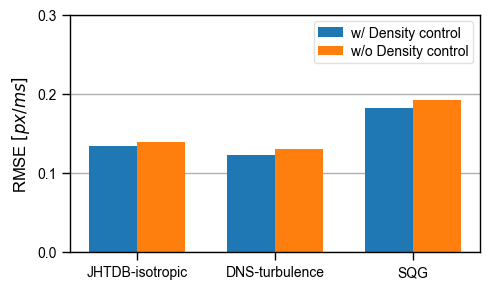

Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/density-control-ablation-100-samples-aee.pdf


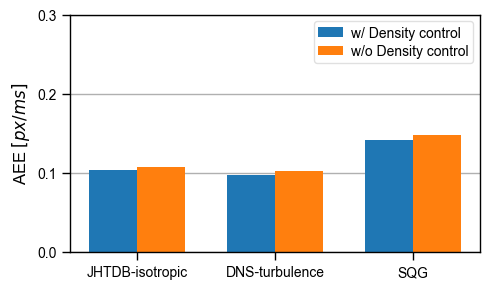

In [3]:
with open(RESULT_PATH, "r", encoding="utf-8") as f:
    saved = json.load(f)
ablation_results = saved["results"]
expected_samples = saved["metadata"]["selected_samples"]
for name in flow_names:
    rows = ablation_results[name]
    actual = {(row["file_idx"], row["file_path"]) for row in rows}
    expected = {(sample["file_idx"], sample["file_path"]) for sample in expected_samples[name]}
    if len(rows) != saved["metadata"]["samples_per_dataset"] or actual != expected:
        raise RuntimeError(f"{name}: incomplete/duplicate results; finish all samples before plotting.")

summary = {}
for flow_name in flow_names:
    rows = ablation_results[flow_name]
    if not rows:
        continue
    summary[flow_name] = {}
    for method in ("adaptive", "fixed"):
        summary[flow_name][method] = {
            metric: {
                "mean": float(np.mean([row[method][metric] for row in rows])),
                "std": float(np.std([row[method][metric] for row in rows])),
            }
            for metric in ("rmse", "aee", "num_gaussians", "elapsed_s")
        }

for flow_name, methods in summary.items():
    print(f"{flow_name} (n={len(ablation_results[flow_name])} distinct samples)")
    for method, metrics in methods.items():
        print(f"  {method:8s} N={metrics['num_gaussians']['mean']:.1f}, "
              f"RMSE={metrics['rmse']['mean']:.4f}, "
              f"AEE={metrics['aee']['mean']:.4f}, "
              f"time={metrics['elapsed_s']['mean']:.1f}s")

ticks_size = 10
legend_size = 10
label_size = 12

x = np.arange(len(flow_names))
width = 0.35
for metric, title in (("rmse", r"RMSE $[px/ms]$"), ("aee", r"AEE $[px/ms]$")):
    # 与 EXP1/EXP2 的单图尺寸一致。
    fig, ax = plt.subplots(figsize=(5, 3))
    for offset, method, label in [(-width / 2, "adaptive", "w/ Density control"),
                                  (width / 2, "fixed", "w/o Density control")]:
        means = [summary[name][method][metric]["mean"] for name in flow_names]
        ax.bar(x + offset, means, width, label=label)
    ax.set_xticks(x)
    ax.set_xticklabels(flow_names, rotation=0, ha="center")
    # 两张图统一纵轴范围，便于比较。
    ax.set_ylim(0.0, 0.3)
    ax.set_yticks([0.0, 0.1, 0.2, 0.3])
    ax.set_ylabel(title, fontsize=label_size)
    ax.tick_params(axis="both", which="major", labelsize=ticks_size,
                   direction="out", length=6, width=1)
    ax.grid(axis="y", which="major", linestyle="-", linewidth=1)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(1)
    ax.legend(loc="upper right", frameon=True, fontsize=legend_size,
              framealpha=0.6, borderpad=0.3, handlelength=1.8,
              handletextpad=0.6, labelspacing=0.35)
    fig.tight_layout()
    pdf_path = DENSITY_OUTPUT_DIR / f"density-control-ablation-100-samples-{metric}.pdf"
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"Saved: {pdf_path}")
    plt.show()


## B. Real-Data Evaluation

Compare six methods using FWL and RSAT on real event recordings.


In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "generator").is_dir() and (path / "methods").is_dir():
            return path
    raise RuntimeError("Run this notebook inside the project directory.")


PROJECT_ROOT = find_project_root()
FLOW_FIELD_DIR = PROJECT_ROOT / "output" / "EXP3" / "flow_fields"
REAL_OUTPUT_DIR = PROJECT_ROOT / "output" / "APPENDIX_real_data_metrics"
REAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from generator.loader import EventManager

real_device = torch.device("cpu")


In [2]:
real_flow_index = 1  # 0: EBIV, 1: Water
real_flow_names = ["ebiv", "water"]
cases = [
    dict(source_type="real", path=str(PROJECT_ROOT / "data/real_old/ebiv_wallflow4_dense.h5")),
    dict(source_type="evk5", path=str(PROJECT_ROOT / "data/water.hdf5")),
]
time_window = (10.0, 20.0)

events, _ = EventManager(**cases[real_flow_index]).load()
mask = (events[:, 2] > time_window[0]) & (events[:, 2] < time_window[1])
evts1 = torch.as_tensor(events[mask], dtype=torch.float32, device=real_device)
del events, mask
if len(evts1) == 0:
    raise ValueError("The selected event window is empty.")
print(f"{real_flow_names[real_flow_index]}: {len(evts1):,} events, {time_window[0]:g}–{time_window[1]:g} ms")


water: 641,302 events, 10–20 ms


In [3]:
# Retrain the two Gaussian methods in this notebook before metric evaluation.
import gc
import random
import time
from dataclasses import asdict

from methods.affinegs.gaussian_flow.config import GaussianFlowConfig
from methods.affinegs.gaussian_flow.training import run_gaussian_flow

if not torch.cuda.is_available():
    raise RuntimeError("ConstGS/AffineGS retraining requires a CUDA GPU.")

gaussian_seed = 2026
gaussian_common_config = dict(
    H=720,
    W=1280,
    init_n=500,
    w_div=100,
    verbose=False,
    tile_size=80,
    init_scale_h=50.0,
    init_scale_w=35.0,
    cmax_sigma=0.6,
    cmax_kernel_size=5,
    lr_j=0.001,
    jacobian_mode="full",
    iterations=300,
    residual_block_size=40,
    prune_opacity_thresh=0.1,
    log_scale_min=float(np.log(8)),
    phase=[50, 200, 250],
)
gaussian_run_configs = {
    "ConstGS": GaussianFlowConfig(enable_jacobian=False, **gaussian_common_config),
    "AffineGS": GaussianFlowConfig(enable_jacobian=True, **gaussian_common_config),
}

FLOW_FIELD_DIR.mkdir(parents=True, exist_ok=True)
gaussian_training_summary = {}
for method_name, cfg in gaussian_run_configs.items():
    random.seed(gaussian_seed)
    np.random.seed(gaussian_seed)
    torch.manual_seed(gaussian_seed)
    torch.cuda.manual_seed_all(gaussian_seed)

    started = time.perf_counter()
    result = run_gaussian_flow(events=evts1, cfg=cfg, flowgt=None)
    elapsed_s = time.perf_counter() - started
    flow = np.asarray(result.flow[:2], dtype=np.float32)
    result_file = FLOW_FIELD_DIR / f"{method_name}-{real_flow_names[real_flow_index]}.npz"
    np.savez_compressed(
        result_file,
        flow=flow,
        method_name=method_name,
        flow_name=real_flow_names[real_flow_index],
        H=cfg.H,
        W=cfg.W,
        event_count=len(evts1),
        time_window_ms=np.asarray(time_window, dtype=np.float64),
        t_min=float(evts1[:, 2].min().item()),
        t_max=float(evts1[:, 2].max().item()),
        seed=gaussian_seed,
        num_gaussians=int(result.model.num_gaussians),
        elapsed_s=float(elapsed_s),
        training_config_json=json.dumps(asdict(cfg), sort_keys=True),
        trained_in="experiments/APPENDIX.ipynb",
    )
    gaussian_training_summary[method_name] = {
        "file": str(result_file),
        "elapsed_s": float(elapsed_s),
        "num_gaussians": int(result.model.num_gaussians),
        "config": asdict(cfg),
    }
    print(
        f"{method_name}: {elapsed_s:.2f}s, "
        f"N_final={result.model.num_gaussians}, saved: {result_file}"
    )
    del result, flow
    gc.collect()
    torch.cuda.empty_cache()


CMax fused extension: OK


Using device: cuda


ConstGS: 2.74s, N_final=320, saved: /media/newdisk/junjie/2dGS-representation/output/EXP3/flow_fields/ConstGS-water.npz


AffineGS: 1.40s, N_final=469, saved: /media/newdisk/junjie/2dGS-representation/output/EXP3/flow_fields/AffineGS-water.npz


### FWL

Measure event-image contrast after motion compensation; higher is better.


In [4]:
import json
import torch.nn.functional as F


@torch.no_grad()
def make_fwl_iwe(events, H, W, t_ref, flow=None, chunk_size=100000):
    """Bilinear-splat count IWE; flow channels are (v_h, v_w)."""
    if events.ndim != 2 or events.shape[1] < 3 or len(events) == 0:
        raise ValueError("events must be a nonempty (N, 4) tensor")
    if flow is not None and flow.shape != (2, H, W):
        raise ValueError(f"flow must have shape (2, {H}, {W})")

    iwe = torch.zeros(H * W, device=events.device, dtype=torch.float32)
    for batch in events.split(chunk_size):
        h, w = batch[:, 0].float(), batch[:, 1].float()
        if flow is not None:
            grid = torch.stack((2 * w / (W - 1) - 1, 2 * h / (H - 1) - 1), dim=-1)
            grid = grid.view(1, 1, -1, 2)
            velocity = F.grid_sample(flow[None], grid, mode="bilinear",
                                     padding_mode="border", align_corners=True)[0, :, 0]
            dt = t_ref - batch[:, 2].float()
            h = h + velocity[0] * dt
            w = w + velocity[1] * dt

        inside = (h >= 0) & (h <= H - 1) & (w >= 0) & (w <= W - 1)
        h, w = h[inside], w[inside]
        if h.numel() == 0:
            continue
        h0, w0 = h.floor().long(), w.floor().long()
        h1, w1 = (h0 + 1).clamp(max=H - 1), (w0 + 1).clamp(max=W - 1)
        dh, dw = h - h0, w - w0
        for hi, wh in ((h0, 1 - dh), (h1, dh)):
            for wi, ww in ((w0, 1 - dw), (w1, dw)):
                iwe.index_add_(0, hi * W + wi, wh * ww)

    return iwe.view(H, W)


@torch.no_grad()
def evaluate_fwl(events, v_h, v_w, H, W, t_ref, unwarped_variance):
    flow = torch.stack((torch.as_tensor(v_h, device=events.device, dtype=torch.float32),
                        torch.as_tensor(v_w, device=events.device, dtype=torch.float32)))
    iwe = make_fwl_iwe(events, H, W, t_ref, flow=flow)
    return dict(fwl=float(iwe.var(unbiased=False).item() / unwarped_variance))


In [5]:
# Load four baseline fields and the two Gaussian fields retrained above.
fwl_method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG", "ConstGS", "AffineGS"]
flow_result_dir = FLOW_FIELD_DIR
flow_result_files = {
    name: flow_result_dir / f"{name}-{real_flow_names[real_flow_index]}.npz"
    for name in fwl_method_names
}
missing_files = [str(path) for path in flow_result_files.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError("Missing saved flow fields:\n" + "\n".join(missing_files))

current_event_count = len(evts1)
current_t_min = float(evts1[:, 2].min().item())
current_t_max = float(evts1[:, 2].max().item())
with np.load(flow_result_files[fwl_method_names[0]], allow_pickle=False) as first_data:
    H, W = int(first_data["H"]), int(first_data["W"])

t_ref = 0.5 * (current_t_min + current_t_max)
unwarped_iwe = make_fwl_iwe(evts1, H, W, t_ref)
unwarped_variance = float(unwarped_iwe.var(unbiased=False).item())
if unwarped_variance <= 0:
    raise ValueError("Unwarped IWE has zero variance; FWL is undefined.")
del unwarped_iwe

fwl_results = {}
for name, flow_file in flow_result_files.items():
    with np.load(flow_file, allow_pickle=False) as data:
        flow = np.asarray(data["flow"], dtype=np.float32)
        saved_method = str(data["method_name"].item())
        saved_flow_name = str(data["flow_name"].item())
        saved_H, saved_W = int(data["H"]), int(data["W"])
        saved_event_count = int(data["event_count"])
        saved_t_min = float(data["t_min"])
        saved_t_max = float(data["t_max"])

    if saved_method != name or saved_flow_name != real_flow_names[real_flow_index]:
        raise ValueError(f"Metadata mismatch in {flow_file}")
    if (saved_H, saved_W) != (H, W) or flow.shape != (2, H, W):
        raise ValueError(f"Flow shape mismatch in {flow_file}: {flow.shape}")
    if (saved_event_count != current_event_count or
            not np.isclose(saved_t_min, current_t_min, atol=1e-6) or
            not np.isclose(saved_t_max, current_t_max, atol=1e-6)):
        raise ValueError(f"Event-window mismatch in {flow_file}; rerun {name}.")

    fwl_results[name] = evaluate_fwl(
        evts1, flow[0], flow[1], H, W, t_ref, unwarped_variance
    )
    print(f"{name:>10s}: FWL={fwl_results[name]['fwl']:.4f}")
    del flow
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

fwl_summary = dict(flow=real_flow_names[real_flow_index], image_size=[H, W],
                   event_count=len(evts1), t_ref=t_ref, methods=fwl_results)
fwl_output_file = REAL_OUTPUT_DIR / f"FWL-{real_flow_names[real_flow_index]}.json"
with open(fwl_output_file, "w") as f:
    json.dump(fwl_summary, f, indent=2)
print(f"saved: {fwl_output_file}")


    ILK_VG: FWL=1.1444


     OF_VG: FWL=1.1536
   INR_EST: FWL=1.1301
    INR_VG: FWL=1.1688
   ConstGS: FWL=1.1942


  AffineGS: FWL=1.2124
saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_real_data_metrics/FWL-water.json


saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_real_data_metrics/FWL-table-water.pdf


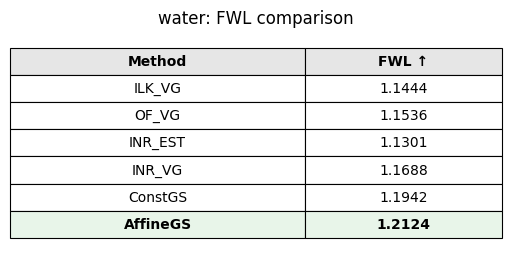

In [6]:
table_method_names = [name for name in fwl_method_names if name in fwl_results]
table_rows = [
    [name, f"{fwl_results[name]['fwl']:.4f}"]
    for name in table_method_names
]
best_row = max(range(len(table_method_names)),
               key=lambda i: fwl_results[table_method_names[i]]["fwl"])

fig, ax = plt.subplots(figsize=(5, 2.5))
ax.axis("off")
ax.set_title(f"{real_flow_names[real_flow_index]}: FWL comparison", fontsize=12, pad=8)
table = ax.table(
    cellText=table_rows,
    colLabels=["Method", "FWL ↑"],
    cellLoc="center", colLoc="center", loc="center",
    colWidths=[0.60, 0.40],
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.0, 1.45)
for col in range(2):
    table[(0, col)].set_facecolor("#E6E6E6")
    table[(0, col)].get_text().set_weight("bold")
    table[(best_row + 1, col)].set_facecolor("#E8F5E9")
    table[(best_row + 1, col)].get_text().set_weight("bold")
for cell in table.get_celld().values():
    cell.set_edgecolor("black")
    cell.set_linewidth(0.8)

fig.tight_layout(pad=0.3)
fwl_table_file = REAL_OUTPUT_DIR / f"FWL-table-{real_flow_names[real_flow_index]}.pdf"
fig.savefig(fwl_table_file, bbox_inches="tight")
print(f"saved: {fwl_table_file}")
plt.show()


### RSAT

Measure timestamp alignment after motion compensation; lower is better.


In [7]:
@torch.no_grad()
def make_rsat_energy(events, H, W, t_ref, flow=None, chunk_size=100000, eps=1e-9):
    """Build polarity-separated average-timestamp images and return their energy."""
    if events.ndim != 2 or events.shape[1] < 4:
        raise ValueError("events must have shape (N, >=4): [row, col, time, polarity].")
    if len(events) == 0:
        raise ValueError("RSAT cannot be evaluated with an empty event window.")

    device = events.device
    dtype = torch.float32
    t_min = float(events[:, 2].min().item())
    t_max = float(events[:, 2].max().item())
    duration = t_max - t_min
    if duration <= 0:
        raise ValueError("RSAT requires a non-zero event-window duration.")

    if flow is not None:
        flow = torch.as_tensor(flow, dtype=dtype, device=device)
        if tuple(flow.shape) != (2, H, W):
            raise ValueError(f"flow must have shape (2, {H}, {W}), got {tuple(flow.shape)}.")

    count_pos = torch.zeros(H * W, dtype=dtype, device=device)
    count_neg = torch.zeros_like(count_pos)
    time_pos = torch.zeros_like(count_pos)
    time_neg = torch.zeros_like(count_pos)

    for start in range(0, len(events), chunk_size):
        batch = events[start:start + chunk_size]
        h = batch[:, 0].to(dtype)
        w = batch[:, 1].to(dtype)
        t = batch[:, 2].to(dtype)
        positive = batch[:, 3] > 0

        if flow is not None:
            grid_w = 2.0 * w / max(W - 1, 1) - 1.0
            grid_h = 2.0 * h / max(H - 1, 1) - 1.0
            grid = torch.stack((grid_w, grid_h), dim=-1).view(1, -1, 1, 2)
            sampled_flow = torch.nn.functional.grid_sample(
                flow.unsqueeze(0), grid, mode="bilinear",
                padding_mode="border", align_corners=True,
            ).view(2, -1)
            dt = float(t_ref) - t
            h = h + sampled_flow[0] * dt
            w = w + sampled_flow[1] * dt

        inside = (h >= 0) & (h <= H - 1) & (w >= 0) & (w <= W - 1)
        if not inside.any():
            continue
        h, w, t, positive = h[inside], w[inside], t[inside], positive[inside]
        t_norm = (t - t_min) / duration

        h0 = torch.floor(h).long()
        w0 = torch.floor(w).long()
        h1 = torch.clamp(h0 + 1, max=H - 1)
        w1 = torch.clamp(w0 + 1, max=W - 1)
        dh = h - h0.to(dtype)
        dw = w - w0.to(dtype)

        neighbours = (
            (h0, w0, (1.0 - dh) * (1.0 - dw)),
            (h0, w1, (1.0 - dh) * dw),
            (h1, w0, dh * (1.0 - dw)),
            (h1, w1, dh * dw),
        )
        for hh, ww, weight in neighbours:
            index = hh * W + ww
            if positive.any():
                idx = index[positive]
                wei = weight[positive]
                count_pos.index_add_(0, idx, wei)
                time_pos.index_add_(0, idx, wei * t_norm[positive])
            negative = ~positive
            if negative.any():
                idx = index[negative]
                wei = weight[negative]
                count_neg.index_add_(0, idx, wei)
                time_neg.index_add_(0, idx, wei * t_norm[negative])

    occupied = (count_pos + count_neg) > eps
    occupied_pixels = int(occupied.sum().item())
    if occupied_pixels == 0:
        raise RuntimeError("No warped event remained inside the image.")

    avg_time_pos = time_pos / (count_pos + eps)
    avg_time_neg = time_neg / (count_neg + eps)
    energy = (avg_time_pos.square().sum() + avg_time_neg.square().sum()) / occupied_pixels
    return float(energy.item())


@torch.no_grad()
def evaluate_rsat(events, v_h, v_w, H, W, t_ref, zero_energy):
    flow = torch.stack((
        torch.as_tensor(v_h, dtype=torch.float32, device=events.device),
        torch.as_tensor(v_w, dtype=torch.float32, device=events.device),
    ))
    energy = make_rsat_energy(events, H, W, t_ref, flow=flow)
    return {"rsat": energy / max(float(zero_energy), 1e-12)}


In [8]:
# Load the same six velocity fields used by FWL.
import json

rsat_method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG", "ConstGS", "AffineGS"]
rsat_flow_name = real_flow_names[real_flow_index]
rsat_flow_field_dir = FLOW_FIELD_DIR
rsat_result_files = {
    name: rsat_flow_field_dir / f"{name}-{rsat_flow_name}.npz"
    for name in rsat_method_names
}
missing = [str(path) for path in rsat_result_files.values() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Missing saved velocity fields. Run the corresponding methods in EXP3 first:\\n"
        + "\n".join(missing)
    )

current_event_count = int(len(evts1))
current_t_min = float(evts1[:, 2].min().item())
current_t_max = float(evts1[:, 2].max().item())
rsat_t_ref = current_t_max
rsat_results = {}

with np.load(rsat_result_files[rsat_method_names[0]], allow_pickle=False) as first_saved:
    H, W = int(first_saved["H"]), int(first_saved["W"])
zero_energy = make_rsat_energy(evts1, H, W, rsat_t_ref, flow=None)

for name, result_file in rsat_result_files.items():
    with np.load(result_file, allow_pickle=False) as saved:
        saved_method = str(saved["method_name"].item())
        saved_flow_name = str(saved["flow_name"].item())
        saved_H, saved_W = int(saved["H"]), int(saved["W"])
        saved_event_count = int(saved["event_count"])
        saved_t_min, saved_t_max = float(saved["t_min"]), float(saved["t_max"])
        if saved_method != name or saved_flow_name != rsat_flow_name:
            raise ValueError(f"Metadata mismatch in {result_file}.")
        if (saved_H, saved_W) != (H, W):
            raise ValueError(f"Image-size mismatch in {result_file}.")
        if saved_event_count != current_event_count or not np.allclose(
            [saved_t_min, saved_t_max], [current_t_min, current_t_max], rtol=0, atol=1e-9
        ):
            raise ValueError(f"Event-window mismatch in {result_file}; rerun {name} above.")
        flow = saved["flow"].astype(np.float32)

    rsat_results[name] = evaluate_rsat(
        evts1, flow[0], flow[1], H, W, rsat_t_ref, zero_energy
    )
    print(f"{name:>8s}: RSAT={rsat_results[name]['rsat']:.6f}")

rsat_summary = {
    "flow_name": rsat_flow_name,
    "event_count": current_event_count,
    "t_min": current_t_min,
    "t_max": current_t_max,
    "reference_time": "t_max",
    "timestamp_normalization": "(t - t_min) / (t_max - t_min)",
    "methods": rsat_results,
}
rsat_output_file = REAL_OUTPUT_DIR / f"RSAT-{rsat_flow_name}.json"
with open(rsat_output_file, "w") as f:
    json.dump(rsat_summary, f, indent=2)
print(f"saved: {rsat_output_file}")


  ILK_VG: RSAT=0.967053
   OF_VG: RSAT=0.967292
 INR_EST: RSAT=0.969046


  INR_VG: RSAT=0.963298
 ConstGS: RSAT=0.957737
AffineGS: RSAT=0.954709
saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_real_data_metrics/RSAT-water.json


saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_real_data_metrics/RSAT-table-water.pdf


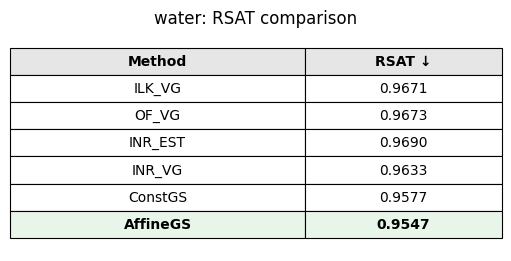

In [9]:
rsat_table_names = [name for name in rsat_method_names if name in rsat_results]
rsat_table_rows = [
    [name, f"{rsat_results[name]['rsat']:.4f}"]
    for name in rsat_table_names
]
best_row = min(range(len(rsat_table_names)),
               key=lambda i: rsat_results[rsat_table_names[i]]["rsat"])

fig, ax = plt.subplots(figsize=(5, 2.5))
ax.axis("off")
ax.set_title(f"{rsat_flow_name}: RSAT comparison", fontsize=12, pad=8)
table = ax.table(
    cellText=rsat_table_rows,
    colLabels=["Method", "RSAT ↓"],
    cellLoc="center", colLoc="center", loc="center",
    colWidths=[0.60, 0.40],
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.0, 1.45)
for col in range(2):
    table[(0, col)].set_facecolor("#E6E6E6")
    table[(0, col)].get_text().set_weight("bold")
    table[(best_row + 1, col)].set_facecolor("#E8F5E9")
    table[(best_row + 1, col)].get_text().set_weight("bold")
for cell in table.get_celld().values():
    cell.set_edgecolor("black")
    cell.set_linewidth(0.8)

fig.tight_layout(pad=0.3)
rsat_table_file = REAL_OUTPUT_DIR / f"RSAT-table-{rsat_flow_name}.pdf"
fig.savefig(rsat_table_file, bbox_inches="tight")
print(f"saved: {rsat_table_file}")
plt.show()
